# 03 · Classification with XGBoost

**Question:** how well can XGBoost forecast the next-year trend of a state's registered crime, and is that
better than a rule anyone could write in one line?

Protocol (from `docs/design.md`): train on feature years up to 2016, early-stop on 2017-18, refit on both, and
score **once** on 2019 onwards. The full tuned comparison is produced by `python -m crimebase train`; this
notebook reads its saved results and re-fits the final XGBoost to look inside it.

In [1]:
import numpy as np
import pandas as pd

from crimebase import viz
from crimebase.config import load_config

cfg = load_config()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_colwidth = 80
pd.options.display.width = 140

import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm notice from optuna, harmless

from crimebase.evaluate import CLASS_NAMES
from crimebase.experiment import final_fit
from crimebase.explain import contributions, importance, signed_effect
from crimebase.features import FEATURES
from crimebase.models import DEFAULTS, fit
from crimebase.pipeline import load_matrix
from crimebase.report import paired_table, scores_table, tuning_table
from crimebase.results import load_comparison, scores_by_year
from crimebase.splits import dev_mask, holdout_mask, train_mask, val_mask

target = "y_trend"
m = load_matrix(cfg)
saved = load_comparison(cfg, target)  # written by `python -m crimebase train`
X, y = m[FEATURES], m[target]
tr, va, dev, te = (f(m, cfg.split, target) for f in (train_mask, val_mask, dev_mask, holdout_mask))

## 1. The task and the bar to beat

In [2]:
s = cfg.split
sizes = pd.DataFrame(
    {"feature years": [f"<= {s.train_to}", f"{s.val_years[0]}-{s.val_years[-1]}", f">= {s.test_from}"],
     "rows": [int(mask.sum()) for mask in (tr, va, te)]},
    index=["train", "validation", "test (held out)"],
)
sizes

,feature years,rows
train,<= 2016,24114
validation,2017-2018,4012
test (held out),>= 2019,12268


In [3]:
baselines = saved.scores.loc[["majority", "persistence", "mean_reversion", "binned_g1"],
                             ["macro_f1", "f1_lo", "f1_hi", "balanced_acc", "accuracy"]]
baselines.index = [viz.label(e) for e in baselines.index]
baselines

,macro_f1,f1_lo,f1_hi,balanced_acc,accuracy
Majority class,0.153,0.145,0.162,0.333,0.298
Persistence rule,0.302,0.285,0.319,0.318,0.316
Mean-reversion rule,0.387,0.371,0.404,0.403,0.394
Last-year-direction table,0.269,0.255,0.283,0.353,0.378


Four opponents that use no machine learning. *Persistence* predicts "next year moves like last year";
*mean reversion* predicts the opposite. Macro-F1 averages the F1 of down, stable and up, so a model cannot score
well by ignoring a class.

## 2. XGBoost with default parameters, and where early stopping stops it

trained on 24,114 rows; stopped after round 215, keeping round 115


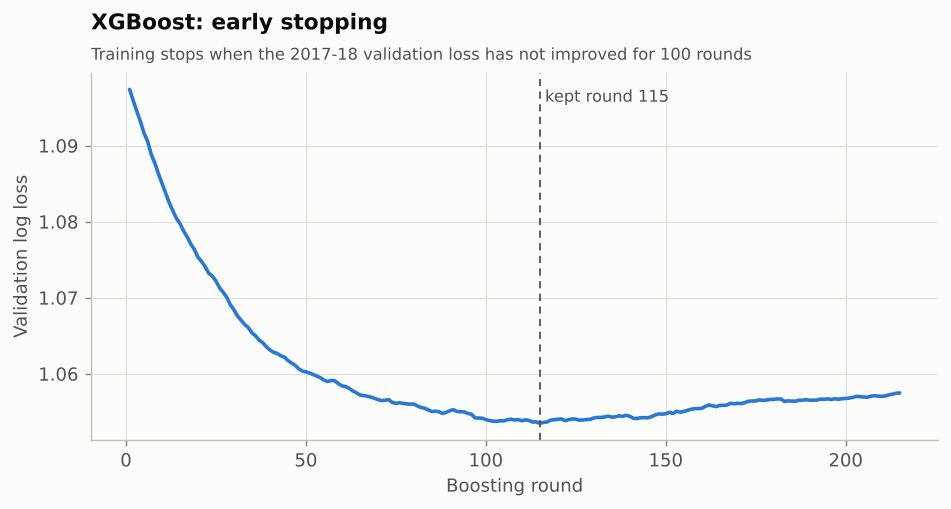

In [4]:
stopped = fit("xgboost", X[tr], y[tr], X[va], y[va], seed=cfg.seed)
history = stopped.model.evals_result()["validation_0"]["mlogloss"]
print(f"trained on {int(tr.sum()):,} rows; stopped after round {len(history)}, keeping round {stopped.best_iteration}")
viz.show(viz.plot_learning_curve(history, stopped.best_iteration, "XGBoost: early stopping"))

## 3. Tuning with Optuna over time-ordered folds

40 trials; cross-validated log loss 1.0408 (default) -> 1.0379 (best)

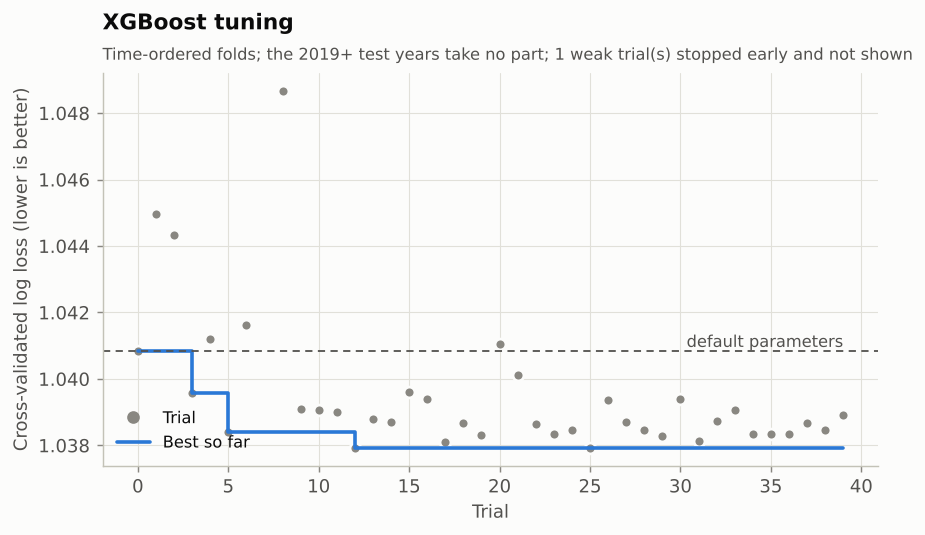

,default,tuned
learning_rate,0.030,0.034
max_depth,5.000,2.000
subsample,0.800,0.600
colsample_bytree,0.700,0.485
min_child_weight,10.000,16.112
reg_lambda,5.000,16.282
reg_alpha,0.000,5.952


In [5]:
tuned = saved.tuning["xgboost"]
trials = pd.read_csv(cfg.paths.metrics / f"{target}_trials_xgboost.csv")
print(f"{tuned['n_trials']} trials; cross-validated log loss {tuned['default_cv_log_loss']:.4f} (default) -> "
      f"{tuned['best_cv_log_loss']:.4f} (best)")
viz.show(viz.plot_tuning(trials, tuned["default_cv_log_loss"], "XGBoost tuning"))
pd.DataFrame({"default": {**DEFAULTS["xgboost"], "reg_alpha": 0.0}, "tuned": tuned["best_params"]})

Each trial is scored on four expanding time folds (validate on 2009-10, 2011-12, 2013-14 and 2017-18, always
training on earlier years). The default parameters are trial 0, so tuning can only match or improve on them
*on those folds*. Whether that carries over to the held-out years is the next section.

## 4. The held-out result

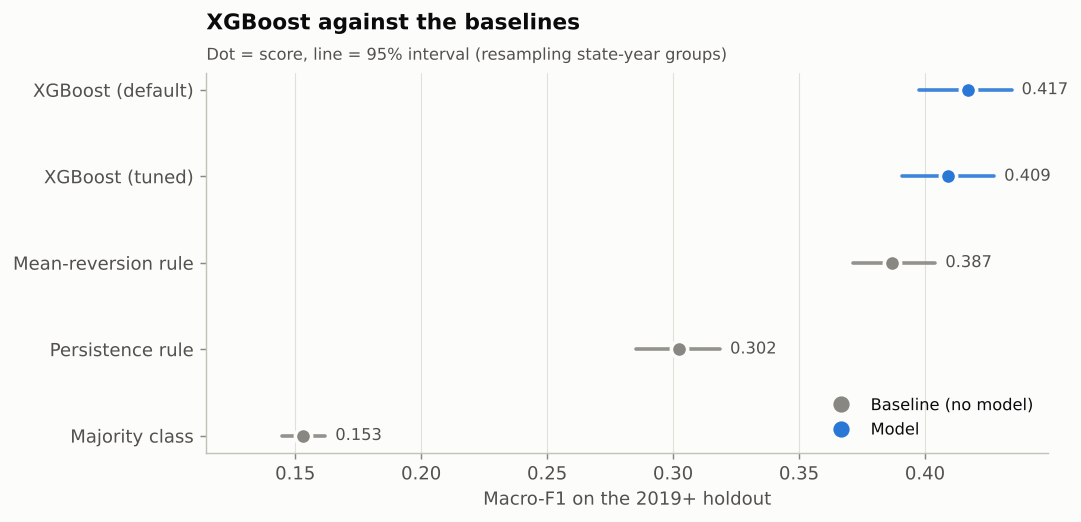

,Macro-F1 [95% CI],Balanced acc.,AUC [95% CI],Log loss,Trees
Model,,,,,
Majority class,"0.153 [0.145, 0.162]",0.333,"0.500 [0.500, 0.500]",1.107,
Persistence rule,"0.302 [0.285, 0.319]",0.318,n/a,n/a,
Mean-reversion rule,"0.387 [0.371, 0.404]",0.403,n/a,n/a,
XGBoost (default),"0.417 [0.398, 0.434]",0.426,"0.609 [0.585, 0.630]",1.069,115
XGBoost (tuned),"0.409 [0.391, 0.427]",0.418,"0.611 [0.589, 0.631]",1.065,181


In [6]:
shown = ["majority", "persistence", "mean_reversion", "xgboost_default", "xgboost_tuned"]
viz.show(viz.plot_scores(saved.scores.loc[shown], title="XGBoost against the baselines"))
scores_table(saved).set_index("Model").loc[[viz.label(e) for e in shown]]

In [7]:
paired = paired_table(saved)
paired[(paired.A.str.contains("XGBoost")) & (paired.B.isin([viz.label("mean_reversion"), viz.label("xgboost_default")]))]

,A,B,Metric,A - B [95% CI],Excludes 0
0,XGBoost (tuned),Mean-reversion rule,macro-F1,"0.022 [0.003, 0.042]",yes
1,XGBoost (tuned),XGBoost (default),macro-F1,"-0.008 [-0.015, -0.0004]",yes
2,XGBoost (tuned),XGBoost (default),AUC,"0.002 [-0.003, 0.007]",no


## 5. Where it is right and wrong

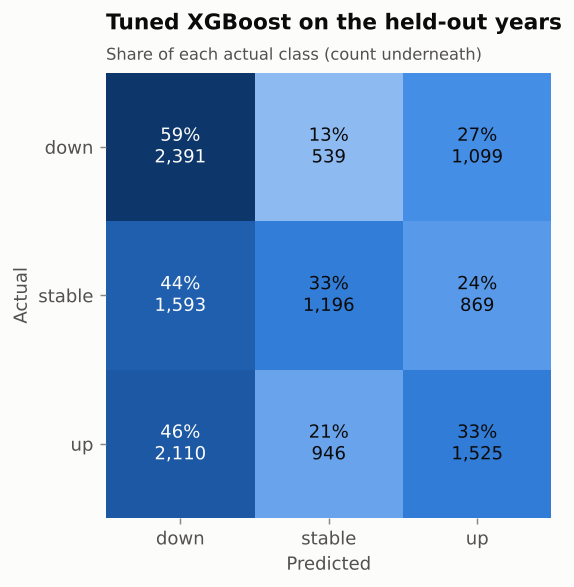

Actual mix of the held-out rows: down 33%, stable 30%, up 37%. Mix the model predicted: down 50%, stable 22%, up 28%.


,f1_down,f1_stable,f1_up
entry,,,
Mean-reversion rule,0.455,0.387,0.319
XGBoost (tuned),0.472,0.377,0.378


In [8]:
from crimebase.report import prediction_mix_sentence

proba = saved.proba("xgboost_tuned").to_numpy()
viz.show(viz.plot_confusion(saved.predictions.y_true, proba, "Tuned XGBoost on the held-out years"))
print(prediction_mix_sentence(saved.predictions.y_true.to_numpy(), proba))
saved.scores.loc[["mean_reversion", "xgboost_tuned"], ["f1_down", "f1_stable", "f1_up"]].rename(index=viz.label)

## 6. Year by year

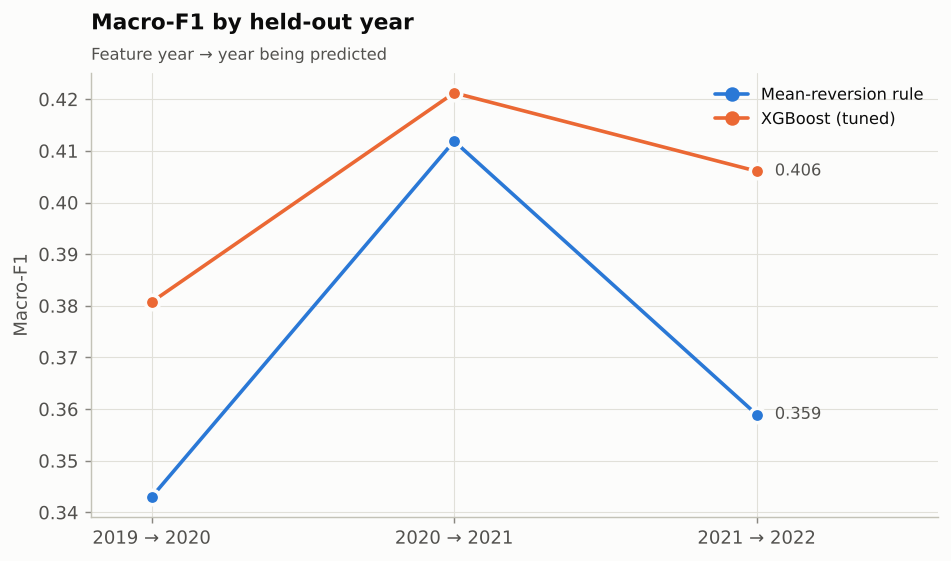

,Mean-reversion rule,XGBoost (tuned)
2019,0.343,0.381
2020,0.412,0.421
2021,0.359,0.406


In [9]:
by_year = scores_by_year(saved, m, cfg, ["mean_reversion", "xgboost_tuned"])
viz.show(viz.plot_by_year(by_year, "Macro-F1 by held-out year"))
by_year.rename(columns=viz.label)

## 7. What the model uses

TreeSHAP gives each feature's push on each class's log-odds for every held-out row; the bars average its size.

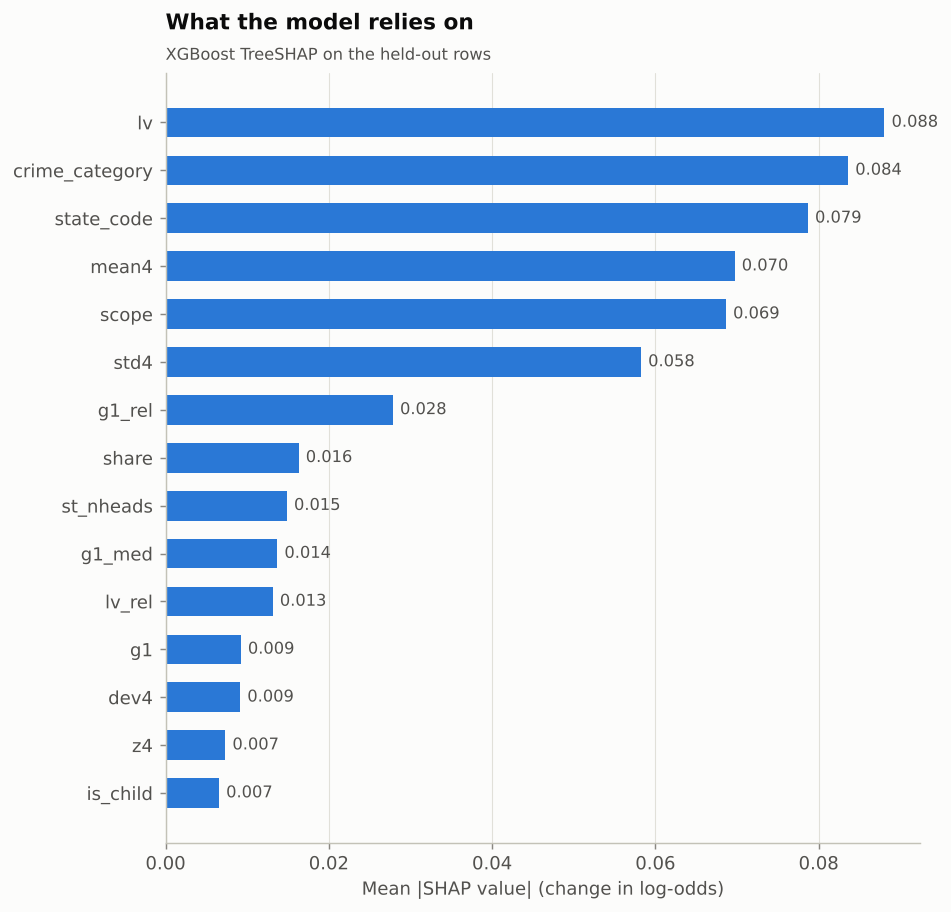

,down,stable,up,total
lv,0.127,0.132,0.006,0.088
crime_category,0.105,0.036,0.109,0.084
state_code,0.056,0.085,0.096,0.079
mean4,0.064,0.140,0.004,0.070
scope,0.029,0.125,0.052,0.069
std4,0.094,0.081,0.001,0.058
g1_rel,0.041,0.010,0.033,0.028
share,0.034,0.000,0.015,0.016
st_nheads,0.024,0.013,0.008,0.015
g1_med,0.007,0.001,0.033,0.014


In [10]:
final, trees = final_fit("xgboost", m, cfg, target, tuned["best_params"])
X_test = X[te]
contrib = contributions(final, X_test)
imp = importance(contrib, FEATURES)
viz.show(viz.plot_importance(imp))
imp.head(10)

In [11]:
effects = pd.concat([signed_effect(contrib, X_test, k) for k in range(3)], axis=1)
effects.loc[[f for f in imp.index[:10] if f in effects.index]]

,down,stable,up
lv,-0.815,0.979,-0.872
mean4,-0.957,0.955,-0.516
std4,0.920,-0.875,0.004
g1_rel,0.808,-0.048,-0.746
share,0.400,NaN,-0.665
st_nheads,0.694,-0.427,-0.713
g1_med,-0.922,0.344,0.847


The table is the rank correlation between a feature's value and its SHAP value for each class: positive means
higher values push that class up. It summarises direction only; trees can use the same feature in opposite
ways in different regions. Read from the table:

* **Bigger series are steadier.** Higher levels (`lv`, `mean4`) push strongly towards *stable* (+0.98, +0.96)
  and away from *down* and *up*; more volatile series (`std4`) are pushed away from *stable*.
* **Relative growth mean-reverts.** A state whose growth ran ahead of other states for the same head
  (`g1_rel`) is pushed towards *down* (+0.81) and away from *up* (−0.75).
* **Common growth persists.** When the median growth across states (`g1_med`) is high, the model leans
  *up* (+0.85) and away from *down* (−0.92).

## 8. Reading the result

* **A real but modest edge.** Tuned XGBoost scores 0.409 macro-F1 against 0.387 for the mean-reversion rule.
  The paired interval for the difference (+0.003 to +0.042) excludes zero, but only just. Its one-vs-rest AUC
  is about 0.61, where 0.50 is chance, so it ranks the right direction only somewhat better than a coin.
* **It beat the rule in every held-out year**, narrowly in 2020→2021 (+0.009) and by about 0.04 in the other two.
* **Tuning found nothing to improve.** The cross-validated log loss fell by only 0.003, the search settled on
  very shallow, heavily regularised trees (depth 2), and on the held-out years the tuned model scored 0.008
  *below* the default. When the best settings are the simplest ones, the signal is simple.
* **What it learned is mostly "what kind of series is this".** The model leans on the level (`lv`), the crime
  category, the state, the scope and the four-year mean and spread of the series, and last year's own growth
  (`g1`) ranks only 12th of 29. Persistent differences in drift and volatility between series matter more
  than short-run momentum.
* **It over-predicts "down" on the held-out years** (about half of rows against a third that really fell).
  The training years all precede 2019, and 2019-2021 includes the 2020 shock, so some of this is distribution
  shift. This project did not isolate the cause.

What would help next: per-capita rates (needs a population table), explicit handling of 2020, and an
early-warning framing (will this head drop or surge by more than 25%?), for which `y_drop` and `y_surge`
are already in the model matrix.